### Diabetes Prediction Using Machine Learning
#### Project Overview

The objective of this project is to build a Machine Learning model to predict diabetes outcomes using the available dataset.

## Technologies Used
-Python
-Pandas
-Numpy
-Matplotlib
-Seaborn
-Scikit-learn

## 1.Importing Libraries
Import the required python libraries for data manipulation,numerical operations ,and data visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2.Loading the Dataset
Load the diabetes dataset into a Pandas DataFrame to inspect  and analyze the data.

In [2]:
df=pd.read_csv("diabetes..csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 3.Understanding the Dataset
In this section,we will explore the structure,size,columns,and datatypes of the dataset

In [3]:
df.shape


(768, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### 4. Data Cleaning
In this section,we will check for missing values and identify invalid zero values in relevant columns.

In [7]:
cols=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
(df[cols]==0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [8]:
df_original=df.copy()

### 5. Handling Invalid Zero Values
In this step,we will replace zero values in selected columns with NaN because they may represent missing measurements.

In [9]:
import numpy as np
cols=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
df[cols]=df[cols].replace(0,np.nan)

In [10]:
df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

### 6.Handling Missing Values
We will fill missing values using the median of each column.The median is less affected by outliers than the mean.

In [11]:
cols=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
for col in cols:
    df[col]=df[col].fillna(df[col].median())

In [12]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

### 7.Exploratory Data Analysis(EDA)
In this section,we will explore the distribution of the target variable and understand the dataset using visualizations.


In [14]:
df["Outcome"].value_counts() #0 :having no diabetes 1:having diabetes

Outcome
0    500
1    268
Name: count, dtype: int64

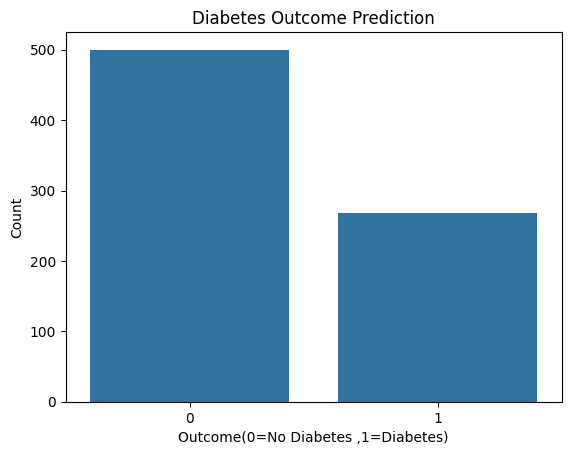

In [15]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.countplot(x='Outcome',data=df)
plt.title('Diabetes Outcome Prediction')
plt.xlabel('Outcome(0=No Diabetes ,1=Diabetes)')
plt.ylabel('Count')
plt.show()

### Correlation Heatmap
In this section,we analyze the correlation between the features using a heatmap.Correlation helps us understand the relationship between different variables in the dataset.



<Axes: >

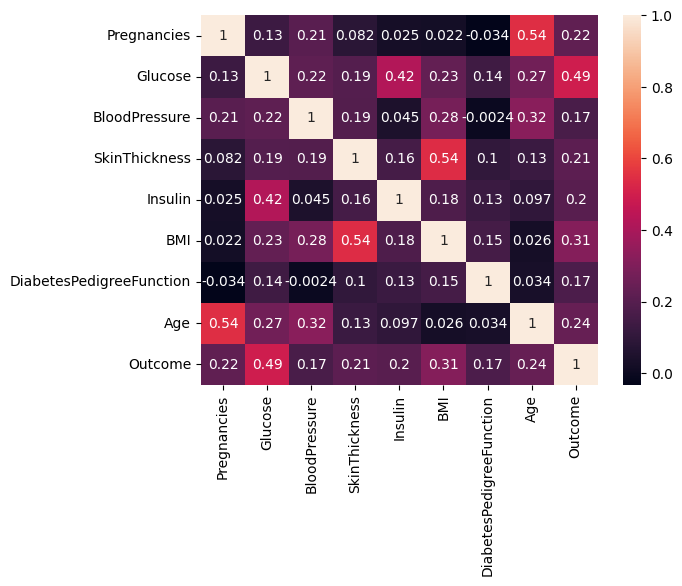

In [16]:
co=df.corr()
co
sns.heatmap(co,annot=True)


### Heatmap Interpretation
The correlation Heatmap shows the relationship between the numerical features in the dataset
. Glucose has a positive correlation with outcome(0.49).
. BMI has a positive correlation with outcome(0.31)
.Age has a positive correlation with outcome(0.24)
.DiabetesPedigreeFunction has a weak positive correlation with outcome(0.17)

Glucose shows the strongest positive correlation with outcome among these features.However,correlation doesnot necessarily imply causation.

### 8. Splitting the Dataset
In this step,we seperate the input features and the target variable.Then,we split the dataset into training and testing sets.
.Input features(X):all columns except Outcome.
.Target Variable(y):Outcome column
.Training Data:Used to train the machinelearning model
.Testing Data:Used to evaluate the model's performance.

In [17]:
X=df.drop('Outcome',axis=1)
y=df['Outcome']
print("Input features shape:",X.shape)
print("Target variable shape:",y.shape)

Input features shape: (768, 8)
Target variable shape: (768,)


### Train-Test Split

In [18]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


### 9.Feature Scaling
Feature scaling brings the input features to a similar scale.It helps logistic regression train more effectively when features have different ranges of values.
In this project,StandardScaler is used to standardize the input features.

In [19]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

### 10.Handling Class Imbalance using SMOTE
The dataset has an imbalance between the the two Outcome classes.SMOTE(Synthetic Minority Over-sampling Technique) generates synthetic samples for the minority class to balance the training dataset.

SMOTE is applied only to the training data to avoid data leakage and preserve the original testdata for evaluation.

In [20]:
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=42)
X_train_resampled,y_train_resampled=smote.fit_resample(X_train_scaled,y_train)

print("Original training distribution:")
print(y_train.value_counts())
print("Resampled  training distribution:")
print(y_train_resampled.value_counts())      
      

Original training distribution:
Outcome
0    400
1    214
Name: count, dtype: int64
Resampled  training distribution:
Outcome
0    400
1    400
Name: count, dtype: int64


### 11. Model Building using Logistic Regression
In this step,we train a Logistic Regression model using the balanced training dataset.The model learns patterns from the input features to predict whether a person has diabetes.

In [21]:
from sklearn.linear_model import LogisticRegression 
model=LogisticRegression(random_state=42)
model.fit(X_train_resampled,y_train_resampled)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### 12.Model Prediction
In this step,we use the trained Logistic Regression model to predict the diabetes outcome for the test data.The model uses the scaled test features to predict whether a person has diabetes or not
.0 indicates No Diabetes
.1 indicates Diabetes

In [22]:
y_pred=model.predict(X_test_scaled)
print(y_pred[:10])

[1 0 0 0 0 0 1 1 0 1]


### 13.Model Evaluation
In this step,we evaluate the performance of the Logistic Regression model using different evaluation metrics such as Accuracy,Precision,recall,F1-Score, and Confusion Matrix
These metrics helps us understand how well the model predicts diabetes outcomes on unseen testdata.

In [23]:
from sklearn.metrics import(accuracy_score,f1_score,precision_score,recall_score,confusion_matrix,classification_report)
print("Accuracy:",accuracy_score(y_test,y_pred))
print("F1-score:",f1_score(y_test,y_pred))
print("Precision:",precision_score(y_test,y_pred))
print("Confusion_matrix:",confusion_matrix(y_test,y_pred))
print("Classification Report:",classification_report(y_test,y_pred))
print("Recall:",recall_score(y_test,y_pred))

Accuracy: 0.7142857142857143
F1-score: 0.6206896551724138
Precision: 0.5806451612903226
Confusion_matrix: [[74 26]
 [18 36]]
Classification Report:               precision    recall  f1-score   support

           0       0.80      0.74      0.77       100
           1       0.58      0.67      0.62        54

    accuracy                           0.71       154
   macro avg       0.69      0.70      0.70       154
weighted avg       0.73      0.71      0.72       154

Recall: 0.6666666666666666


### 14.Conclusion
In this project,I developed a Diabetes Prediction model using Logistic Regression.
The dataset was explored and preprocessed by handling missing values,checking duplicates,and performing data visualization.The data was split into training and testing sets.Feature scaling and SMOTE were applied before training the model.
The model was evaluated using accuracy,precision,recall,F1-score,and a confusion matrix.The model acheived approximately 71% accuracy on the test dataset.

This project helped me understand the basic workflow of a machine learning classification problem.